# Predição de Turnover com XGBoost

Projeto completo de People Analytics utilizando o dataset Employee Turnover.

## Objetivos
- Entender os fatores associados ao turnover.
- Construir modelos preditivos.
- Comparar Logistic Regression, Random Forest e XGBoost.
- Interpretar resultados com SHAP.
- Gerar um modelo pronto para uso.


In [1]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import shap
import joblib


## Carregamento dos Dados

In [3]:
import zipfile
import os

# Define o caminho para o arquivo zip
zip_file_path = '/content/archive (1).zip'

# Define o diretório de destino para a extração
extract_dir = '/content/'

# Cria o diretório de destino se ele não existir
os.makedirs(extract_dir, exist_ok=True)

# Extrai o arquivo zip
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print(f"Arquivo '{zip_file_path}' extraído para '{extract_dir}' com sucesso!")

# Verifica se o arquivo 'turnover.csv' foi extraído
if 'turnover.csv' in os.listdir(extract_dir):
    print("\n'turnover.csv' encontrado após a extração.")
else:
    print("\n'turnover.csv' NÃO encontrado após a extração. Verifique o conteúdo do zip.")

Arquivo '/content/archive (1).zip' extraído para '/content/' com sucesso!

'turnover.csv' encontrado após a extração.


In [6]:
df = pd.read_csv('turnover.csv', encoding='latin1')
df.head()

,stag,event,gender,age,industry,profession,traffic,coach,head_gender,greywage,way,extraversion,independ,selfcontrol,anxiety,novator
0,7.030801,1,m,35.0,Banks,HR,rabrecNErab,no,f,white,bus,6.2,4.1,5.7,7.1,8.3
1,22.965092,1,m,33.0,Banks,HR,empjs,no,m,white,bus,6.2,4.1,5.7,7.1,8.3
2,15.934292,1,f,35.0,PowerGeneration,HR,rabrecNErab,no,m,white,bus,6.2,6.2,2.6,4.8,8.3
3,15.934292,1,f,35.0,PowerGeneration,HR,rabrecNErab,no,m,white,bus,5.4,7.6,4.9,2.5,6.7
4,8.410678,1,m,32.0,Retail,Commercial,youjs,yes,f,white,bus,3.0,4.1,8.0,7.1,3.7


In [7]:

print(df.shape)
df.info()


(1129, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1129 entries, 0 to 1128
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   stag          1129 non-null   float64
 1   event         1129 non-null   int64  
 2   gender        1129 non-null   object 
 3   age           1129 non-null   float64
 4   industry      1129 non-null   object 
 5   profession    1129 non-null   object 
 6   traffic       1129 non-null   object 
 7   coach         1129 non-null   object 
 8   head_gender   1129 non-null   object 
 9   greywage      1129 non-null   object 
 10  way           1129 non-null   object 
 11  extraversion  1129 non-null   float64
 12  independ      1129 non-null   float64
 13  selfcontrol   1129 non-null   float64
 14  anxiety       1129 non-null   float64
 15  novator       1129 non-null   float64
dtypes: float64(7), int64(1), object(8)
memory usage: 141.3+ KB


In [8]:

df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
stag,1129.0,NaN,NaN,NaN,36.627526,34.096597,0.394251,11.728953,24.344969,51.318275,179.449692
event,1129.0,NaN,NaN,NaN,0.505757,0.500188,0.0,0.0,1.0,1.0,1.0
gender,1129,2,f,853,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1129.0,NaN,NaN,NaN,31.066965,6.996147,18.0,26.0,30.0,36.0,58.0
industry,1129,16,Retail,289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
profession,1129,15,HR,757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic,1129,8,youjs,318,NaN,NaN,NaN,NaN,NaN,NaN,NaN
coach,1129,3,no,683,NaN,NaN,NaN,NaN,NaN,NaN,NaN
head_gender,1129,2,m,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
greywage,1129,2,white,1002,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Análise da Variável Alvo

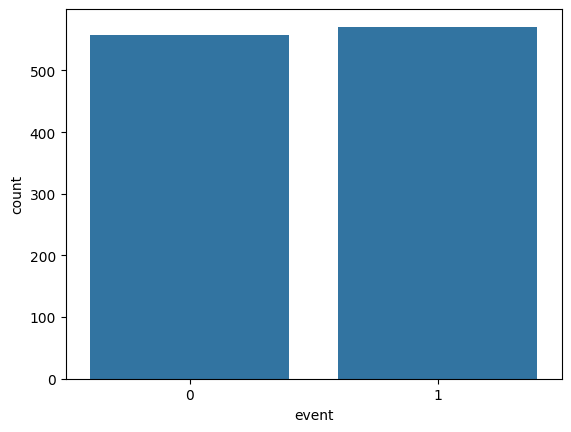

event
1    50.575731
0    49.424269
Name: proportion, dtype: float64


In [9]:

sns.countplot(data=df, x='event')
plt.show()

print(df['event'].value_counts(normalize=True)*100)


## Missing Values

In [10]:

df.isnull().sum().sort_values(ascending=False)


,0
stag,0
event,0
gender,0
age,0
industry,0
profession,0
traffic,0
coach,0
head_gender,0
greywage,0


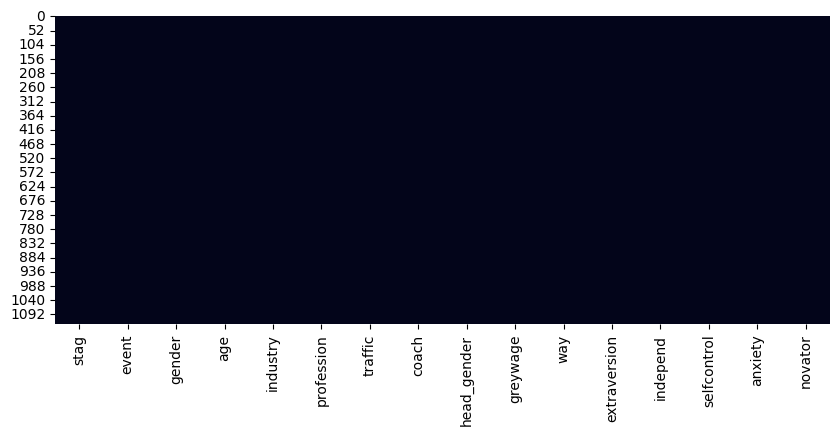

In [11]:

plt.figure(figsize=(10,4))
sns.heatmap(df.isnull(), cbar=False)
plt.show()


## EDA

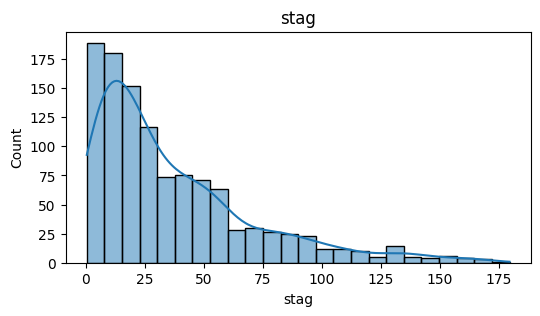

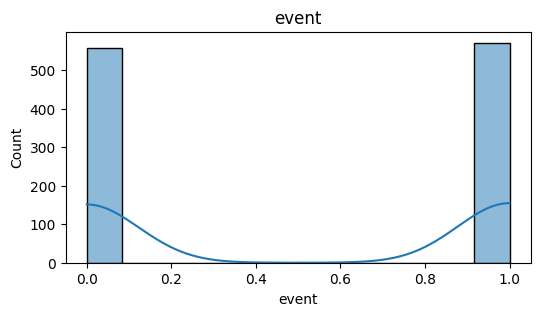

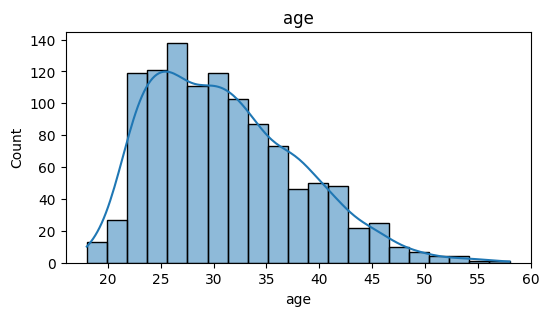

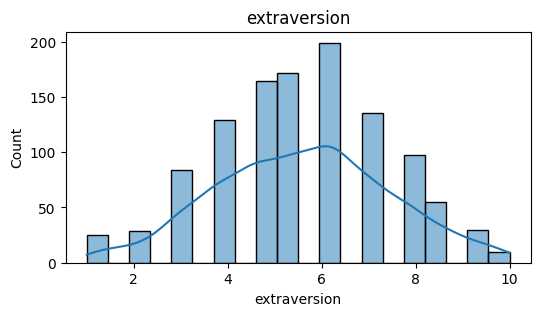

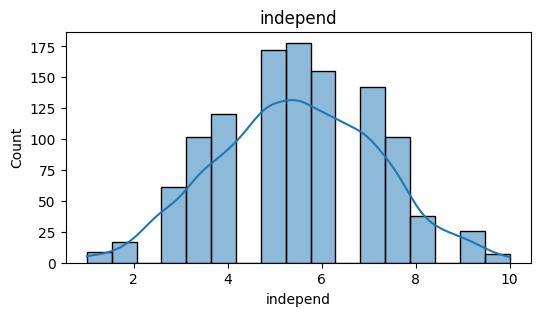

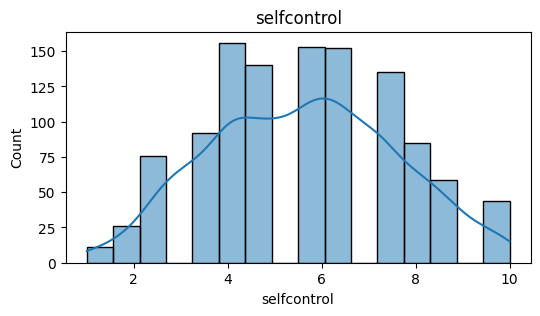

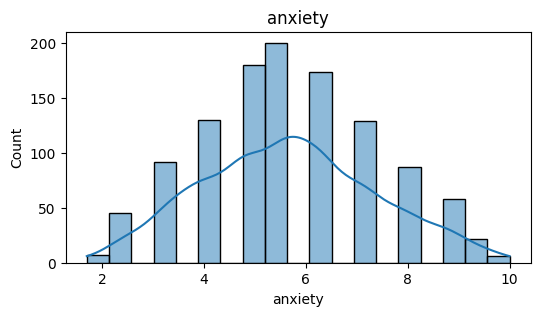

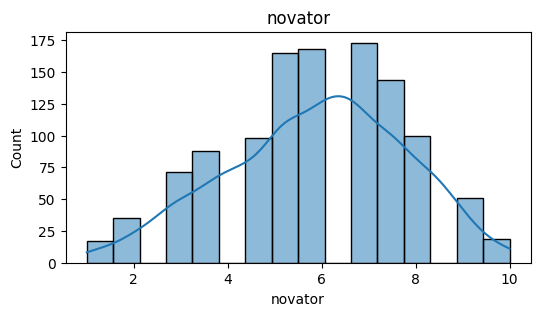

In [12]:

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns

for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()


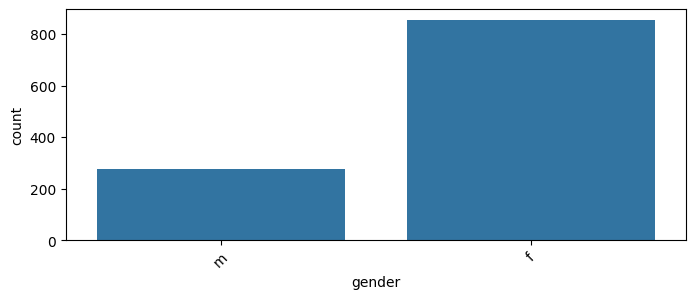

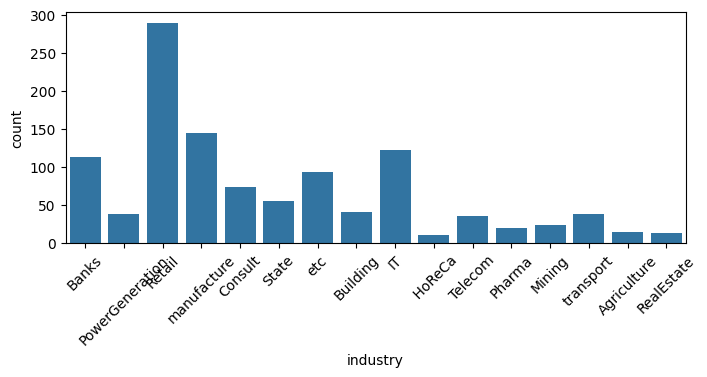

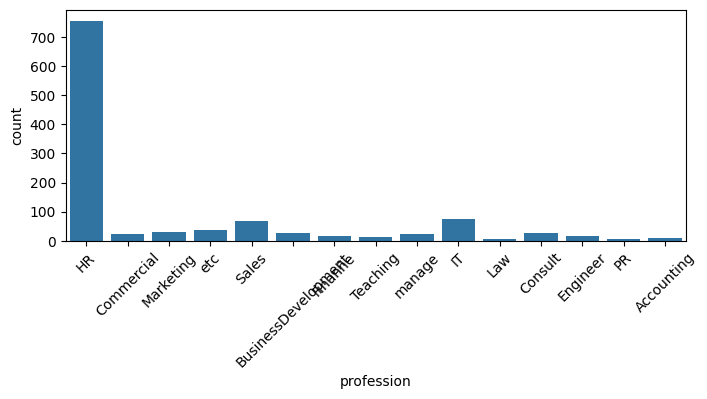

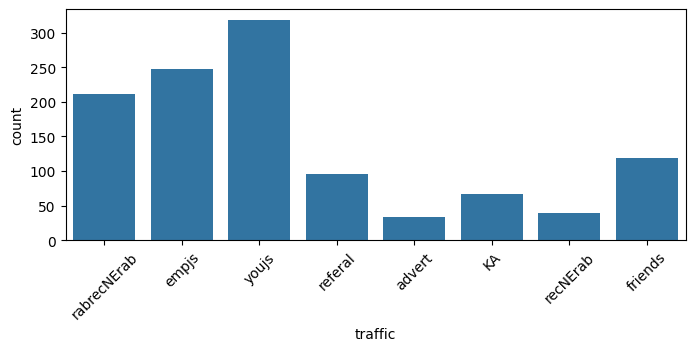

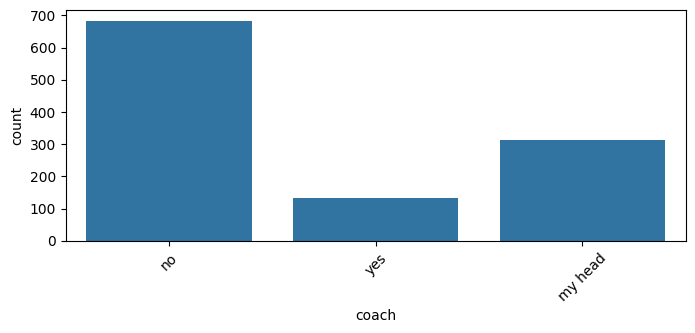

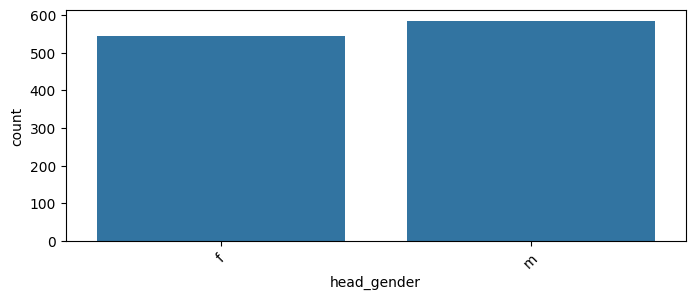

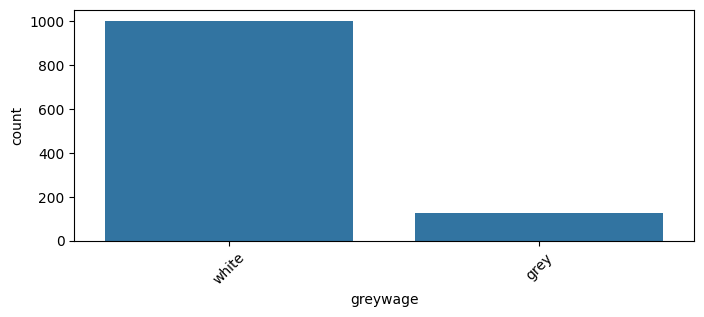

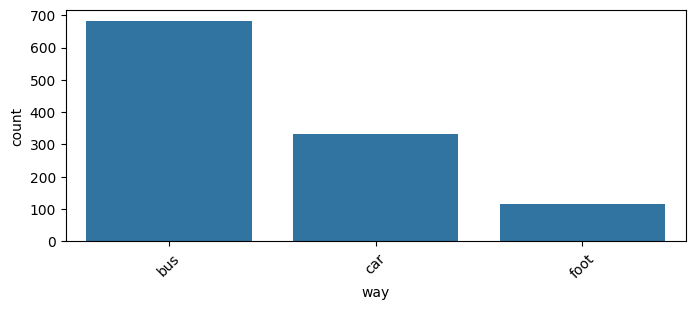

In [13]:

for col in cat_cols:
    plt.figure(figsize=(8,3))
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)
    plt.show()


## Preparação dos Dados

In [14]:

X = df.drop('event', axis=1)
y = df['event']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cat_features = X.select_dtypes(include='object').columns
num_features = X.select_dtypes(exclude='object').columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])


## Modelos

In [15]:

log_model = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=500))
])

rf_model = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

xgb_model = Pipeline([
    ('prep', preprocessor),
    ('model', XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='logloss'
    ))
])

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['stag', 'age', 'extraversion', 'independ', 'selfcontrol', 'anxiety',
       'novator'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'industry', 'profession', 'traffic', 'coach', 'head_gender',
       'greywage', 'way'],
      dtype='object'))])),
                ('model',
                 XGBClas...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [16]:

def evaluate_model(model):

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]

    print(classification_report(y_test, pred))

    print('ROC AUC:', roc_auc_score(y_test, prob))

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()


Logistic Regression
              precision    recall  f1-score   support

           0       0.60      0.58      0.59       112
           1       0.60      0.61      0.61       114

    accuracy                           0.60       226
   macro avg       0.60      0.60      0.60       226
weighted avg       0.60      0.60      0.60       226

ROC AUC: 0.6540570175438597


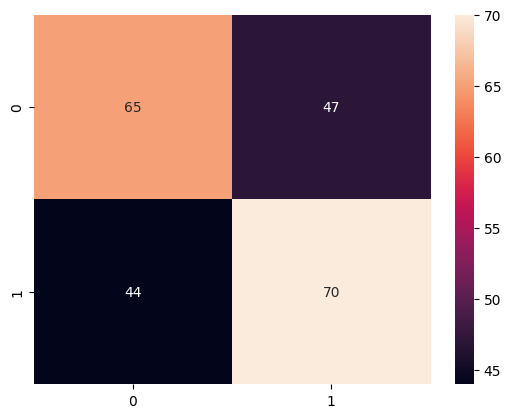

Random Forest
              precision    recall  f1-score   support

           0       0.70      0.67      0.68       112
           1       0.69      0.72      0.70       114

    accuracy                           0.69       226
   macro avg       0.70      0.69      0.69       226
weighted avg       0.69      0.69      0.69       226

ROC AUC: 0.7649592731829574


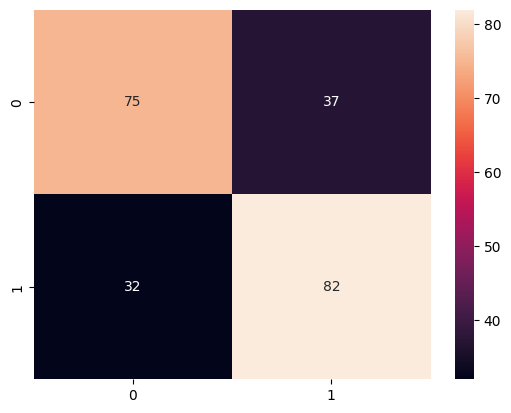

XGBoost
              precision    recall  f1-score   support

           0       0.66      0.61      0.63       112
           1       0.64      0.69      0.67       114

    accuracy                           0.65       226
   macro avg       0.65      0.65      0.65       226
weighted avg       0.65      0.65      0.65       226

ROC AUC: 0.7221177944862156


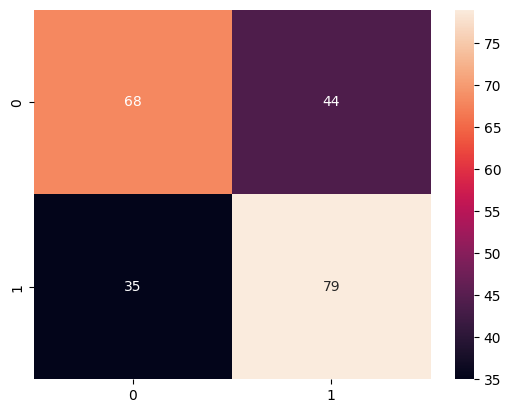

In [17]:

print('Logistic Regression')
evaluate_model(log_model)

print('Random Forest')
evaluate_model(rf_model)

print('XGBoost')
evaluate_model(xgb_model)


## Cross Validation

In [18]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    xgb_model,
    X,
    y,
    scoring='roc_auc',
    cv=cv
)

print(scores)
print(scores.mean())


[0.79921661 0.7462406  0.72713033 0.70245927 0.71392445]
0.7377942518360139


## SHAP

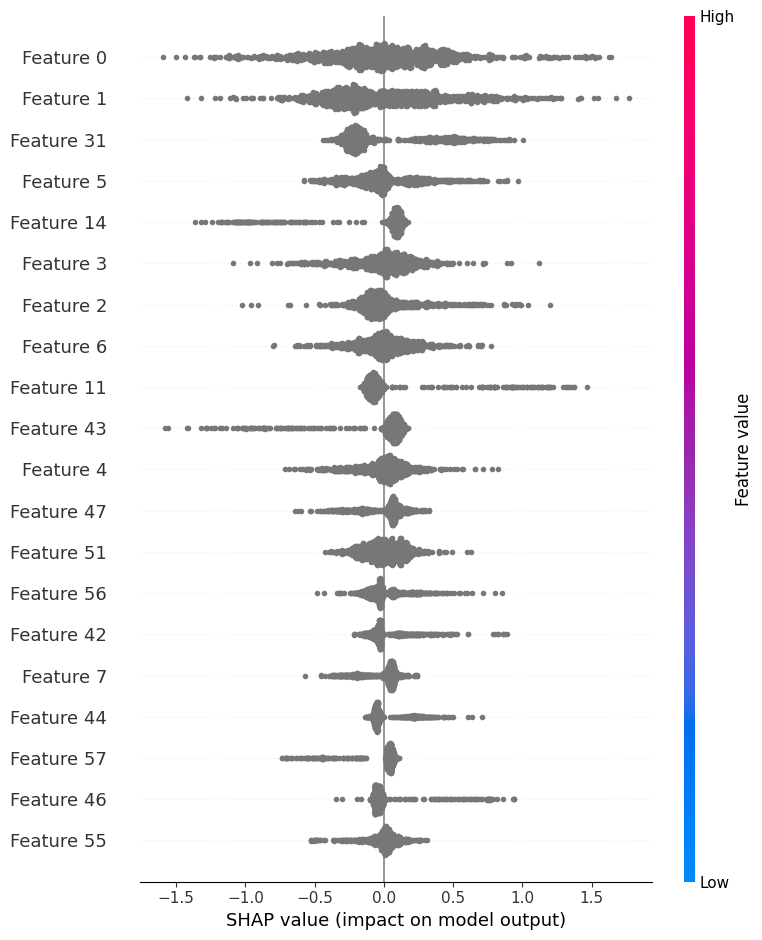

In [19]:

X_processed = preprocessor.fit_transform(X)

xgb_final = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

xgb_final.fit(X_processed, y)

explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_processed)

shap.summary_plot(shap_values, X_processed)


## Feature Importance

In [20]:

importance = pd.DataFrame({
    'feature': preprocessor.get_feature_names_out(),
    'importance': xgb_final.feature_importances_
}).sort_values('importance', ascending=False)

importance.head(20)


,feature,importance
14,cat__industry_IT,0.071294
57,cat__way_foot,0.047588
43,cat__traffic_friends,0.034613
19,cat__industry_Retail,0.031935
20,cat__industry_State,0.031621
11,cat__industry_Banks,0.029104
42,cat__traffic_empjs,0.025850
31,cat__profession_HR,0.025821
51,cat__head_gender_f,0.024790
46,cat__traffic_referal,0.024550


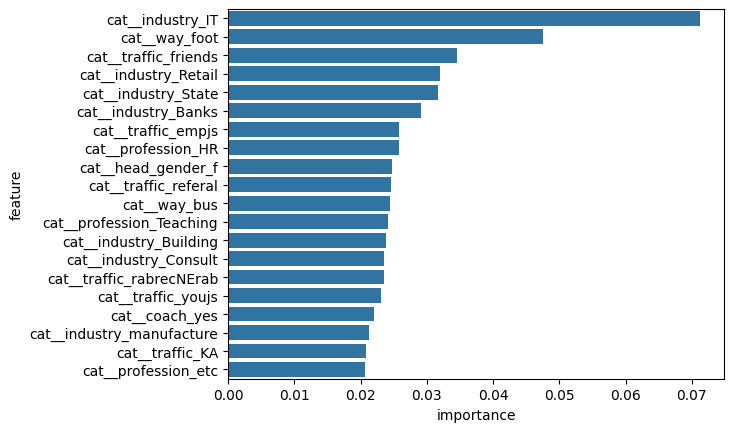

In [21]:

sns.barplot(
    data=importance.head(20),
    x='importance',
    y='feature'
)
plt.show()


## Persistência do Modelo

In [22]:

joblib.dump(
    xgb_model,
    'turnover_xgboost.pkl'
)


['turnover_xgboost.pkl']